# Using genomic-benchmarks-data4agents

This tutorial demonstrates dataset discovery, metadata, loading, caching, and quality-control (QC) results with the agent-safe package. It exposes `train` and `val` data where available, but never `test` data or `test`-related QC.

You will learn how to:

- discover collections, datasets, and the benchmark core set;
- present dictionary results in a human-readable form;
- inspect available filter values and metadata;
- load data and locate cached files; and
- explore QC results, summaries, and self-contained reports.

Install the package if it is not already available in this environment:

```python
%pip install genomic-benchmarks-data4agents
```

In [2]:
from IPython.display import display
import pandas as pd
import genomic_benchmarks_data4agents as gbd

from utils import display_qc_report

## Discover datasets

Package discovery functions return ordinary Python dictionaries that can be used directly in code. The next cell shows the raw result first, followed by the same dictionary rendered with `pretty()` for easier reading.

In [2]:
collections = gbd.list_collections()
collections

{'BEACON': 'https://doi.org/10.52202/079017-2949',
 'GUE_v2': 'https://doi.org/10.48550/arXiv.2306.15006',
 'OmniGenBench': 'https://doi.org/10.48550/arXiv.2505.14402',
 'genomic-benchmarks': 'https://doi.org/10.1186/s12863-023-01123-8',
 'mRNABench': 'https://doi.org/10.1101/2025.07.05.662870',
 'miRBench': 'https://doi.org/10.1093/bioinformatics/btaf233',
 'nucleotide_benchmarks': 'https://doi.org/10.1038/s41592-024-02523-z'}

In [3]:
gbd.pretty(collections)

BEACON,https://doi.org/10.52202/079017-2949
GUE_v2,https://doi.org/10.48550/arXiv.2306.15006
OmniGenBench,https://doi.org/10.48550/arXiv.2505.14402
genomic-benchmarks,https://doi.org/10.1186/s12863-023-01123-8
mRNABench,https://doi.org/10.1101/2025.07.05.662870
miRBench,https://doi.org/10.1093/bioinformatics/btaf233
nucleotide_benchmarks,https://doi.org/10.1038/s41592-024-02523-z


### Select the core set

The core set is a selected subset of benchmarks. Pass `core_set=True` to select it, or `core_set=False` to select its complement. Core-set selection can be combined with the other dataset filters.

In [4]:
core_datasets = gbd.list_datasets(core_set=True)
gbd.pretty(core_datasets)

{'BEACON': {'CRISPROnTarget': 'Prediction of the knockout efficacy of single-guide RNA '
                              '(sgRNA) directed by Cas proteins in gene editing within '
                              'specific target sites.'},
 'GUE_v2': {'transcription_factor_prediction_mouse_4': 'Prediction of transcription '
                                                       'factor binding sites (mouse, '
                                                       'subset 4)',
            'epigenetic_marks_prediction_H3K4me3': 'Prediction of epigenetic marks '
                                                   '(H3K4me3 histone modifications) in '
                                                   'yeast'},
 'OmniGenBench': {'pro_seq_m_esculenta': 'Prediction of enhancer elements in Manihot '
                                         'esculenta seedlings (plant)',
                  'promoter_strength_protoplast': 'Prediction of promoter strength in '
                                                  'protoplasts (plant)'},
 'genomic-benchmarks': {'drosophila_enhancers_stark': 'Prediction of enhancers'},
 'mRNABench': {'translation-efficiency-human': 'Prediction of translation efficiency '
                                               'from sequence.',
               'rnahl-human': 'Prediction of mRNA half-life from sequence. Target is '
                              'first PCA component of half-life measurments across 39 '
                              'human aggregated datasets. '},
 'miRBench': {'AGO2_eCLIP_Manakov2022': 'Prediction of miRNA binding site'}}

This tutorial uses the small core-set dataset `BEACON/CRISPROnTarget`, which provides `train` and `val` splits. Change the two values in the next cell to explore another dataset.

In [5]:
COLLECTION = "BEACON"
DATASET = "CRISPROnTarget"

### Explore available filter values

`list_dataset_filters()` shows the filters accepted by `list_datasets()` and their currently available values. 

In [6]:
filter_values = gbd.list_dataset_filters()
gbd.pretty(filter_values)


collection,BEACONGUE_v2OmniGenBenchgenomic-benchmarksmRNABenchmiRBenchnucleotide_benchmarks
molecular_level,DNARNA
task_category,Engineering PredictionEpigenomic PredictionMolecular Interaction PredictionRNA / Transcript ClassificationRNA Processing PredictionRNA Stability PredictionSequence AnnotationSpecies ClassificationTranslation Efficiency Prediction
task_type,Binary classificationRegression
species,Arabidopsis thalianaChlamydomonas reinhardtiiDrosophila melanogasterGlycine maxHomo sapiensHomo sapiens|Caenorhabditis elegansManihot esculentaMedicago truncatulaMus musculusNicotiana tabacumOryza sativaSaccharomyces cerevisiaeSolanum lycopersicumSorghum bicolorTrifolium pratenseTriticum aestivumZea mays
core_set,TrueFalse


Passing `COLLECTION` limits the metadata-derived values to the selected collection; omit it to inspect values across the entire package.

In [7]:
filter_values = gbd.list_dataset_filters(COLLECTION)
gbd.pretty(filter_values)

collection,BEACON
molecular_level,DNARNA
task_category,Engineering PredictionRNA Processing PredictionTranslation Efficiency Prediction
task_type,Regression
species,Homo sapiens
core_set,TrueFalse


## Inspect metadata

Use the targeted accessors for ordinary exploration. `load_metadata()` is also available when the complete packaged metadata is needed for bulk processing.

In [8]:
dataset_info = gbd.get_dataset_info(COLLECTION, DATASET)
gbd.pretty(dataset_info)

dataset_name,CRISPROnTarget
task_description,Prediction of the knockout efficacy of single-guide RNA (sgRNA) directed by Cas proteins in gene editing within specific target sites.
dataset_doi,https://doi.org/10.1186/s13059-018-1459-4
species,Homo sapiens
task_type,Regression
seq_col,seq
label_col,label
label_categories,None
splits,trainval
major_version,v1
task_category,Engineering Prediction


In [9]:
split_info = gbd.get_split_info(COLLECTION, DATASET, "train")
gbd.pretty(split_info)

{'seq_length': {'seq': {'min': 23, 'max': 23, 'median': 23}},
 'seq_alphabet': {'seq': ['A', 'C', 'G', 'T']},
 'labels': {'min': 0.0277828845416346,
            'max': 0.692699498961697,
            'median': 0.216143386109033},
 'dataset_size': 1453,
 'class_ratio': None,
 'all_columns': ['id', 'row_index', 'seq', 'label'],
 'sha256': '66cf1af39463cfb3acb9aca56c13fde6e2c31cd170470e874e761d52d6e19db5'}

Only the splits listed in this package are accessible. `test` and `test_leftout` files, metadata, and related QC are not included.

## Download and load data

`download_dataset()` downloads the complete cached file and returns its path. The example displays only portable file details rather than the machine-specific cache path.

In [6]:
gbd.download_dataset(COLLECTION, DATASET, "val")

PosixPath('/homes/ssamm10/.cache/genomic_benchmarks_data4agents/data/BEACON/CRISPROnTarget/v1/val/0e21e3f7b58487289173c8b1ee692175ee661cd85528c44ff84a200b06ab1549/CRISPROnTarget_val.csv.gz')

`load_dataset()` downloads and loads the dataset in a Pandas DataFrame. By default, `train` and `val` contain the sequence and label columns needed for the task.

In [11]:
train = gbd.load_dataset(COLLECTION, DATASET, "train")
train.head()

,seq,label
0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,TTCATTTACTGACTTCAGATTGG,0.088202
2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


The `val` view has the same sequence-and-label default as `train`. Validation data can be used during model development without exposing held-out test data.

In [12]:
validation = gbd.load_dataset(COLLECTION, DATASET, "val")
validation.head()

,seq,label
0,ACTCTTGATGCTCTGCTCCATGG,0.167180
1,AAGCAGATTCCACGAATCCTCGG,0.181103
2,GCTCTTACCAGAGAGTTCTCTGG,0.167319
3,ACAAGGGAGAGGAGGAACTGCGG,0.280896
4,TTAGTGCTGCTTCCTCCTGAAGG,0.301213


Use `columns="all"` to include identifiers and any other auxiliary columns for `train` and `val` splits.

In [13]:
train_all = gbd.load_dataset(COLLECTION, DATASET, "train", columns="all")
train_all.head()

,id,row_index,seq,label
0,BEACON:CRISPROnTarget:v1:train:0000000,0,TTCACTGCGCAGCCTGGCATTGG,0.261026
1,BEACON:CRISPROnTarget:v1:train:0000001,1,TTCATTTACTGACTTCAGATTGG,0.088202
2,BEACON:CRISPROnTarget:v1:train:0000002,2,AAAGAGGTCGAAGATGTAGCGGG,0.103584
3,BEACON:CRISPROnTarget:v1:train:0000003,3,CAAGATTGATCAGAAAGCTGTGG,0.274124
4,BEACON:CRISPROnTarget:v1:train:0000004,4,TTCACTGCCAGTTCTCCGCGTGG,0.315928


## Explore QC results

Class QC compares classes in individual splits. Split QC compares two splits for leakage. Use `list_qc_metrics()` to discover the checks available for each QC type.

In [14]:
class_qc_metrics = gbd.list_qc_metrics("class")
gbd.pretty(class_qc_metrics)

['Duplicate Sequences between Labels',
 'Per position nucleotide content',
 'Per position reversed nucleotide content',
 'Per sequence GC content',
 'Per sequence dinucleotide content',
 'Per sequence nucleotide content',
 'Sequence Duplications within Labels',
 'Sequence lengths',
 'Unique bases']

In [15]:
split_qc_metrics = gbd.list_qc_metrics("split")
gbd.pretty(split_qc_metrics)

['Data Leakage']

### Inspect QC for the selected dataset

The first result contains every class-QC check for the `train` split. The second contains every detailed QC check for the `train`–`val` comparison.

In [16]:
class_qc = gbd.get_class_qc_results(COLLECTION, DATASET, "train")
gbd.pretty(class_qc)


{'Unique bases': {'flag': 'Pass', 'accuracy': None, 'au_pr': None, 'au_roc': None},
 'Sequence Duplications within Labels': {'flag': 'Pass',
                                         'accuracy': None,
                                         'au_pr': None,
                                         'au_roc': None},
 'Duplicate Sequences between Labels': {'flag': 'Pass',
                                        'accuracy': None,
                                        'au_pr': None,
                                        'au_roc': None},
 'Sequence lengths': {'flag': 'Pass',
                      'accuracy': 0.5003441156228493,
                      'au_pr': 0.5003441156228493,
                      'au_roc': 0.5},
 'Per sequence GC content': {'flag': 'Pass',
                             'accuracy': 0.5375086028905712,
                             'au_pr': 0.5226575903860866,
                             'au_roc': 0.5447734188199362},
 'Per sequence nucleotide content': {'flag': 'Warning',
                                     'accuracy': 0.578114246386786,
                                     'au_pr': 0.5667324855945897,
                                     'au_roc': 0.6020884725711536},
 'Per sequence dinucleotide content': {'flag': 'Pass',
                                       'accuracy': 0.5746730901582932,
                                       'au_pr': 0.5615124254838183,
                                       'au_roc': 0.5904022720641453},
 'Per position nucleotide content': {'flag': 'Pass',
                                     'accuracy': 0.5788024776324845,
                                     'au_pr': 0.5514016412079391,
                                     'au_roc': 0.5789614287175873},
 'Per position reversed nucleotide content': {'flag': 'Pass',
                                              'accuracy': 0.5788024776324845,
                                              'au_pr': 0.5514016412079391,
                                              'au_roc': 0.5789614287175873}}

In [17]:
split_qc = gbd.get_split_qc_results(COLLECTION, DATASET, "train", "val")
gbd.pretty(split_qc)

{'Data Leakage': {'flag': 'Pass',
                  'percentage_of_leaked_queries': '0.00%',
                  'percentage_of_leaked_targets': '0.00%'}}

### Filter datasets by QC results

In [18]:
passing_class_qc = gbd.filter_datasets_by_qc("class", flag="Pass")
gbd.pretty(passing_class_qc)

GUE_v2,enhancer_promoter_interaction_GM12878enhancer_promoter_interaction_HeLa_S3enhancer_promoter_interaction_K562epigenetic_marks_prediction_H3K14acepigenetic_marks_prediction_H3K4me3transcription_factor_prediction_mouse_0transcription_factor_prediction_mouse_1transcription_factor_prediction_mouse_4
OmniGenBench,promoter_strength_protoplast
genomic-benchmarks,drosophila_enhancers_stark
miRBench,AGO2_CLASH_Hejret2023AGO2_eCLIP_Manakov2022


In [19]:
passing_split_qc = gbd.filter_datasets_by_qc("split", flag="Pass")
gbd.pretty(passing_split_qc)


BEACON,CRISPROnTargetMeanRibosomeLoading
GUE_v2,epigenetic_marks_prediction_H3epigenetic_marks_prediction_H3K14acepigenetic_marks_prediction_H3K4me3epigenetic_marks_prediction_H4actranscription_factor_prediction_mouse_0transcription_factor_prediction_mouse_2transcription_factor_prediction_mouse_4
mRNABench,rnahl-humanrnahl-mousetranslation-efficiency-humantranslation-efficiency-mouse


### Compare QC across collections

The plots summarize QC flags by collection. For class QC, each dataset–split–check result contributes one observation. For split QC, each dataset–split-pair–check result contributes one observation. Each bar is normalized over the included results for that collection, so its segments show the proportions marked `Pass`, `Warning`, `Fail`, or `Unknown`. Passing `check=...` restricts the calculation to that check. Available QC checks can be listed with `list_qc_metrics()`.

In this package, split QC contains only available `train`–`val` comparisons, so collections without such a comparison do not appear in the split plot.

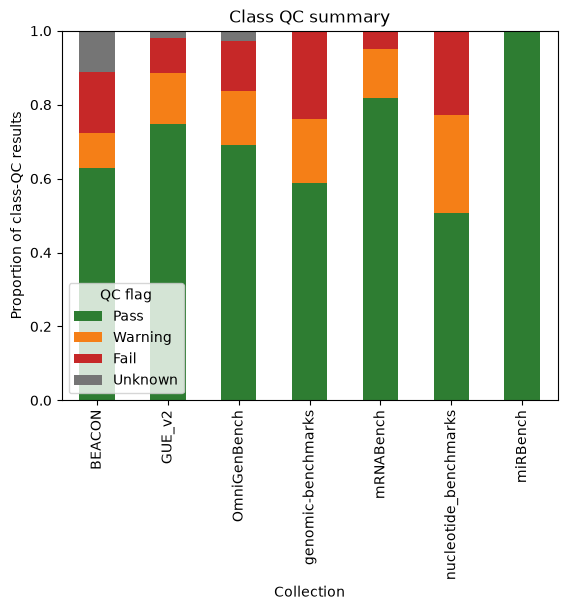

In [20]:
class_summary_plot = gbd.plot_qc_summary("class")


In [21]:
class_qc_metrics = gbd.list_qc_metrics("class")
gbd.pretty(class_qc_metrics)

['Duplicate Sequences between Labels',
 'Per position nucleotide content',
 'Per position reversed nucleotide content',
 'Per sequence GC content',
 'Per sequence dinucleotide content',
 'Per sequence nucleotide content',
 'Sequence Duplications within Labels',
 'Sequence lengths',
 'Unique bases']

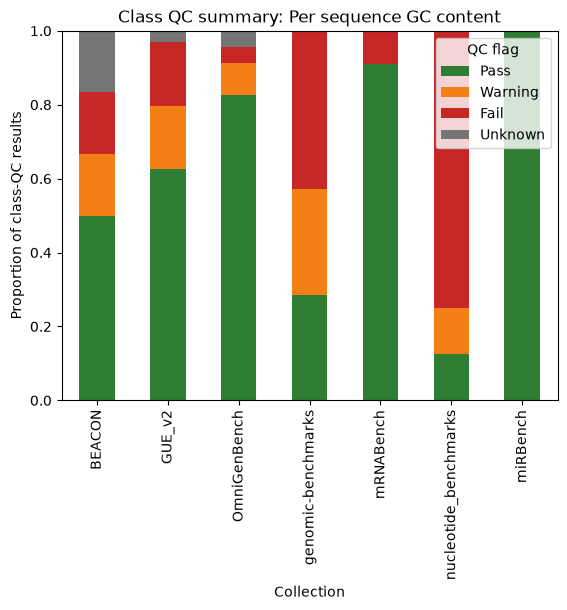

In [22]:
class_summary_plot_gc_content = gbd.plot_qc_summary("class", check="Per sequence GC content")

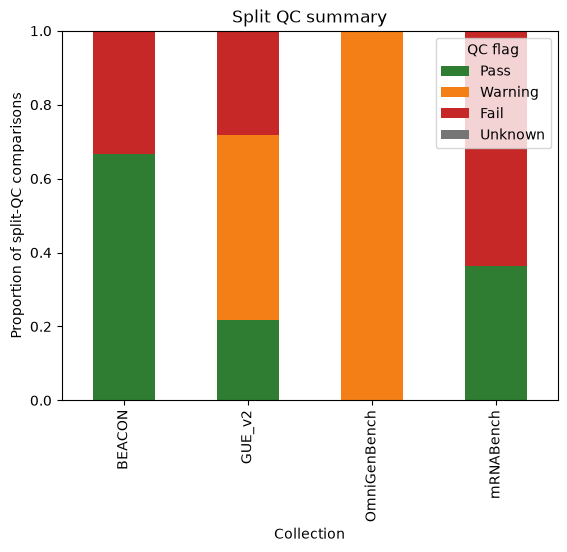

In [23]:
split_summary_plot = gbd.plot_qc_summary("split")


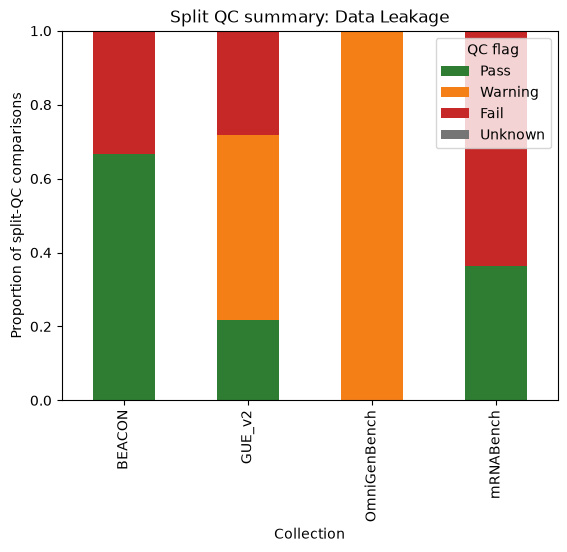

In [3]:
class_summary_plot_gc_content = gbd.plot_qc_summary("split", check="Data Leakage")

## Open self-contained QC reports

Run these cells locally to explore the interactive reports. Their large embedded HTML output is intentionally not stored in the repository notebooks.

In [ ]:
class_report = gbd.get_class_qc_report(COLLECTION, DATASET, split="train", seq_col="seq")
display_qc_report(class_report)

In [ ]:
split_report = gbd.get_split_qc_report(COLLECTION, DATASET, split_a="train", split_b="val")
display_qc_report(split_report)